# Machine Maintenance Prediction — Data Cleaning

Run this notebook **one cell at a time**, from top to bottom (Shift+Enter in VS Code), using the `.venv` kernel.

**Before starting:** make sure `proj_machine_readings.csv` is in the repo's `data/` folder (this notebook lives at the repo root).

This notebook preserves the original vibration field, creates `vibration_abs`, flags missing temperatures before imputing them with each machine's median, and does not remove statistical outliers.

## Step 1 — Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

## Step 2 — Set the path to the original CSV

In [2]:
# The raw CSV lives in the data/ folder (relative to the repo root)
input_file = "data/proj_machine_readings.csv"

print("Using file:", input_file)

Using file: data/proj_machine_readings.csv


## Step 3 — Load the dataset

In [3]:
df = pd.read_csv(input_file)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (100000, 13)


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,1/1/2025 0:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,1/1/2025 0:01,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,1/1/2025 0:02,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,1/1/2025 0:03,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,1/1/2025 0:04,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


## Step 4 — Inspect the column names and data types

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

Column names:
['timestamp', 'machine_id', 'temperature', 'vibration', 'humidity', 'pressure', 'energy_consumption', 'machine_status', 'anomaly_flag', 'predicted_remaining_life', 'failure_type', 'downtime_risk', 'maintenance_required']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000

## Step 5 — Generate a statistical summary

In [5]:
display(df.describe(include="all"))

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
count,100000,100000.000000,86000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000,100000.000000,100000.000000
unique,100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN
top,1/1/2025 0:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Normal,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,91899,NaN,NaN
mean,NaN,25.499330,75.034410,43.324232,54.995401,3.000405,2.747064,1.002050,0.089160,234.269160,NaN,0.089155,0.196970
std,NaN,14.389439,10.036257,29.134306,14.437960,1.152399,1.297865,0.446193,0.284976,150.063062,NaN,0.284961,0.397711
min,NaN,1.000000,35.550000,-106.980000,30.000000,1.000000,0.500000,0.000000,0.000000,1.000000,NaN,0.000000,0.000000
25%,NaN,13.000000,68.280000,37.220000,42.520000,2.000000,1.630000,1.000000,0.000000,97.000000,NaN,0.000000,0.000000
50%,NaN,25.000000,75.090000,48.635000,54.980000,3.010000,2.740000,1.000000,0.000000,230.000000,NaN,0.000000,0.000000
75%,NaN,38.000000,81.780000,59.250000,67.500000,4.000000,3.870000,1.000000,0.000000,365.000000,NaN,0.000000,0.000000


## Step 6 — Check missing values before cleaning

In [6]:
missing_before = df.isnull().sum()

missing_percentage = (missing_before / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing values": missing_before,
    "Missing percentage": missing_percentage.round(2)
})

display(missing_summary)

,Missing values,Missing percentage
timestamp,0,0.0
machine_id,0,0.0
temperature,14000,14.0
vibration,0,0.0
humidity,0,0.0
pressure,0,0.0
energy_consumption,0,0.0
machine_status,0,0.0
anomaly_flag,0,0.0
predicted_remaining_life,0,0.0


## Step 7 — Create a temperature missing indicator

Create this indicator **before** filling missing temperatures:
- `1` means the original temperature was missing.
- `0` means the original temperature was present.

This preserves information about missing sensor readings.

In [7]:
df["temperature_missing"] = df["temperature"].isnull().astype(int)

print("Temperature missing indicator:")
print(df["temperature_missing"].value_counts())

Temperature missing indicator:
temperature_missing
0    86000
1    14000
Name: count, dtype: int64


## Step 8 — Impute temperature using each machine's median

In [8]:
# Fill missing temperature values with the median temperature
# of the corresponding machine.
df["temperature"] = df.groupby("machine_id")["temperature"].transform(
    lambda machine_values: machine_values.fillna(machine_values.median())
)

# Fallback: if a machine has no valid temperature readings at all,
# fill any remaining missing values with the overall median.
df["temperature"] = df["temperature"].fillna(df["temperature"].median())

print("Missing temperatures after imputation:",
      df["temperature"].isnull().sum())

Missing temperatures after imputation: 0


## Step 9 — Preserve vibration and create absolute vibration

The vibration unit/sign convention has not been confirmed. Keep the original `vibration` column unchanged and create a separate magnitude field, `vibration_abs`.

Do not delete negative vibration readings at this stage.

In [9]:
df["vibration_abs"] = df["vibration"].abs()

print("Negative values in original vibration:",
      (df["vibration"] < 0).sum())

display(df[["vibration", "vibration_abs"]].head(10))

Negative values in original vibration: 6703


,vibration,vibration_abs
0,-28.65,28.65
1,57.28,57.28
2,50.20,50.20
3,37.65,37.65
4,40.69,40.69
5,38.38,38.38
6,40.70,40.70
7,56.52,56.52
8,24.98,24.98
9,49.29,49.29


## Step 10 — Examine absolute vibration by failure type

In [10]:
vibration_by_failure = df.groupby(
    "failure_type", observed=False
)["vibration_abs"].agg(["count", "median", "mean", "max"])

display(vibration_by_failure)

,count,median,mean,max
failure_type,,,,
Electrical Fault,1014,48.715,48.969763,95.02
Normal,91899,49.980,50.026809,113.80
Overheating,1989,50.030,49.835636,103.50
Pressure Drop,1969,49.760,49.883763,91.28
Vibration Issue,3129,50.220,50.228626,109.71


**Interpretation note:** The vibration field has shown almost no relationship with `Vibration Issue`. Treat it as a questionable sensor and investigate its usefulness during EDA and model evaluation. Do not assume that `vibration_abs` is automatically a strong predictor.

## Step 11 — Check exact duplicate rows

In [11]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


## Step 12 — Check repeated readings for the same machine and timestamp

In [12]:
repeated_machine_time = df.duplicated(
    subset=["machine_id", "timestamp"]
).sum()

print("Repeated machine_id + timestamp combinations:",
      repeated_machine_time)

# Do not automatically remove these rows.
# Investigate them first if any are found.

Repeated machine_id + timestamp combinations: 0


## Step 13 — Remove exact duplicate rows, if any

In [13]:
# Remove only exact duplicate rows.
# This does not remove repeated machine-time combinations unless
# the entire row is identical.
df = df.drop_duplicates().copy()

print("Dataset shape after exact duplicate check:", df.shape)

Dataset shape after exact duplicate check: (100000, 15)


## Step 14 — Convert timestamp into datetime format

The raw timestamps are written **day-first** (`d/m/yyyy h:mm`, e.g. `15/1/2025 19:33`). Without a format,
`pd.to_datetime` guesses **month-first** from the first value (`1/1/2025`), which turns every reading whose day is
above 12 into `NaT` and swaps day and month on the rest. Passing the explicit format `%d/%m/%Y %H:%M` parses every
row correctly. `src/clean_machine_readings.py` uses the same format.

In [14]:
# Raw timestamps are day-first, e.g. 15/1/2025 19:33
TIMESTAMP_FORMAT = "%d/%m/%Y %H:%M"

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    format=TIMESTAMP_FORMAT,
    errors="coerce"
)

print("Timestamp data type:", df["timestamp"].dtype)
print("Invalid or missing timestamps:", df["timestamp"].isnull().sum())

Timestamp data type: datetime64[us]
Invalid or missing timestamps: 0


## Step 15 — Validate categorical values

In [15]:
print("Machine status values:")
print(df["machine_status"].value_counts(dropna=False))

print("\nAnomaly flag values:")
print(df["anomaly_flag"].value_counts(dropna=False))

print("\nFailure type values:")
print(df["failure_type"].value_counts(dropna=False))

print("\nMaintenance required values:")
print(df["maintenance_required"].value_counts(dropna=False))

Machine status values:
machine_status
1    80091
2    10057
0     9852
Name: count, dtype: int64

Anomaly flag values:
anomaly_flag
0    91084
1     8916
Name: count, dtype: int64

Failure type values:
failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64

Maintenance required values:
maintenance_required
0    80303
1    19697
Name: count, dtype: int64


## Step 16 — Check for unexpected category labels

In [16]:
expected_values = {
    "machine_status": {0, 1, 2},
    "anomaly_flag": {0, 1},
    "failure_type": {
        "Normal",
        "Vibration Issue",
        "Overheating",
        "Pressure Drop",
        "Electrical Fault"
    },
    "maintenance_required": {0, 1}
}

for column, allowed_values in expected_values.items():
    observed_values = set(df[column].dropna().unique())
    unexpected_values = observed_values - allowed_values

    print(f"{column} - unexpected values: {unexpected_values}")

machine_status - unexpected values: set()
anomaly_flag - unexpected values: set()
failure_type - unexpected values: set()
maintenance_required - unexpected values: set()


## Step 17 — Inspect the target variable distribution

maintenance_required
0    80303
1    19697
Name: count, dtype: int64


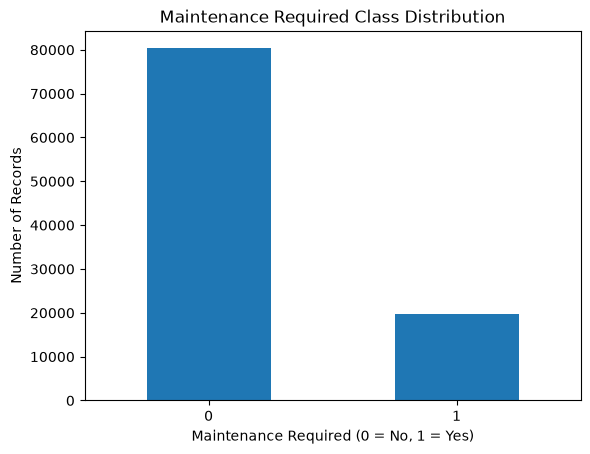

In [17]:
target_counts = df["maintenance_required"].value_counts().sort_index()

print(target_counts)

target_counts.plot(
    kind="bar",
    title="Maintenance Required Class Distribution",
    xlabel="Maintenance Required (0 = No, 1 = Yes)",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.show()

## Step 18 — Inspect sensor distributions using boxplots

Boxplots help identify unusual readings. In this project, extreme readings may indicate machine faults.

**Do not automatically delete or cap high values just because they fall outside statistical outlier boundaries.**

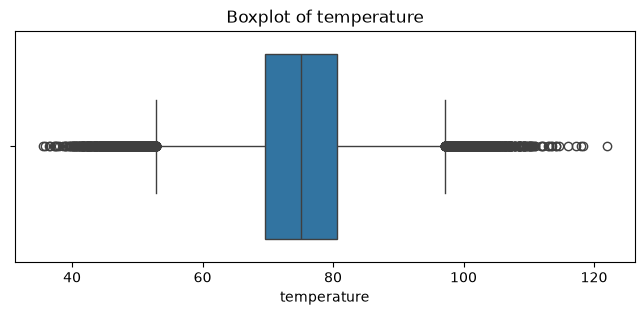

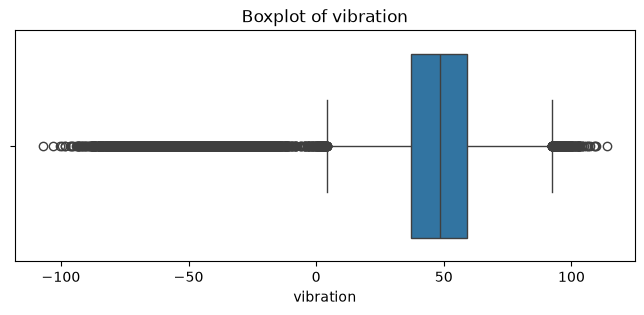

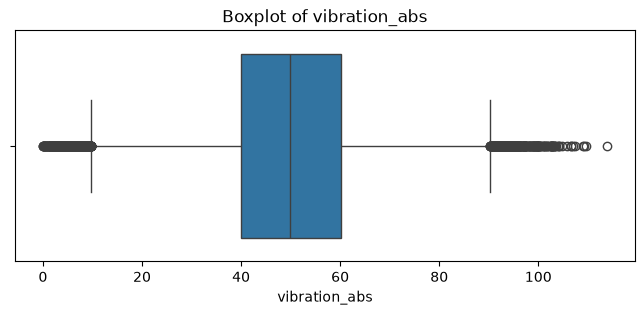

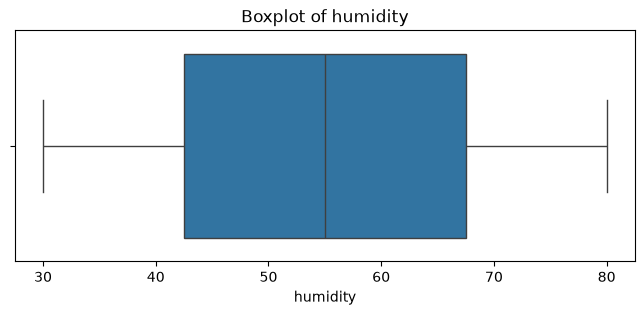

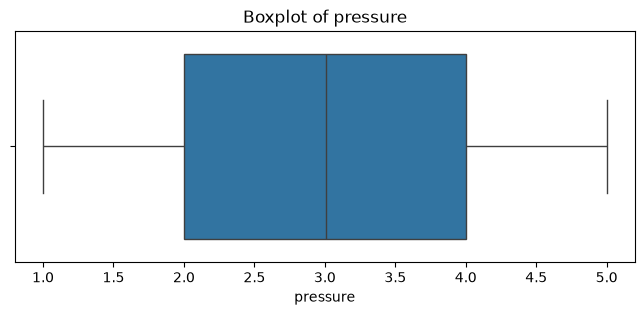

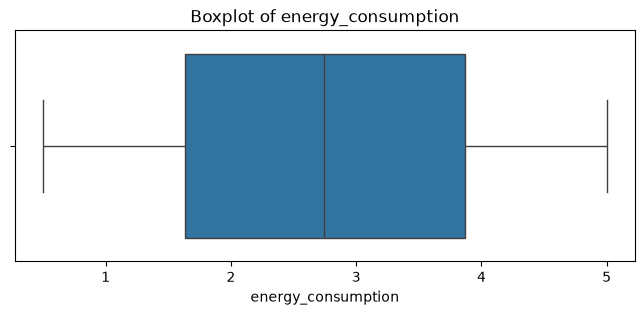

In [18]:
sensor_columns = [
    "temperature",
    "vibration",
    "vibration_abs",
    "humidity",
    "pressure",
    "energy_consumption"
]

for column in sensor_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

## Step 19 — Count statistical outliers for investigation only

In [19]:
# The IQR fences are used only to flag unusual observations.
# No rows or values are removed or changed in this step.

outlier_results = []

for column in sensor_columns:
    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_fence) | (values > upper_fence)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Lower fence": lower_fence,
        "Upper fence": upper_fence,
        "Values outside fences": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(3))

,Column,Lower fence,Upper fence,Values outside fences
0,temperature,52.880,97.200,2313
1,vibration,4.175,92.295,6999
2,vibration_abs,9.775,90.295,714
3,humidity,5.050,104.970,0
4,pressure,-1.000,7.000,0
5,energy_consumption,-1.730,7.230,0


## Step 20 — Final missing-value check

In [20]:
print("Missing values after cleaning:")
display(df.isnull().sum())

print("Final dataset shape:", df.shape)

Missing values after cleaning:


timestamp                   0
machine_id                  0
temperature                 0
vibration                   0
humidity                    0
pressure                    0
energy_consumption          0
machine_status              0
anomaly_flag                0
predicted_remaining_life    0
failure_type                0
downtime_risk               0
maintenance_required        0
temperature_missing         0
vibration_abs               0
dtype: int64

Final dataset shape: (100000, 15)


## Step 21 — Final duplicate check

In [21]:
print("Final exact duplicate count:", df.duplicated().sum())

Final exact duplicate count: 0


## Step 22 — Final check of the new columns

In [22]:
print("Number of originally missing temperatures:",
      df["temperature_missing"].sum())

print("Missing temperature values remaining:",
      df["temperature"].isnull().sum())

print("Missing vibration_abs values:",
      df["vibration_abs"].isnull().sum())

display(df[[
    "machine_id",
    "temperature",
    "temperature_missing",
    "vibration",
    "vibration_abs"
]].head(10))

Number of originally missing temperatures: 14000
Missing temperature values remaining: 0
Missing vibration_abs values: 0


,machine_id,temperature,temperature_missing,vibration,vibration_abs
0,39,74.46,1,-28.65,28.65
1,29,68.19,0,57.28,57.28
2,15,98.94,0,50.20,50.20
3,43,90.91,0,37.65,37.65
4,8,72.32,0,40.69,40.69
5,21,70.88,0,38.38,38.38
6,39,73.05,0,40.70,40.70
7,19,90.00,0,56.52,56.52
8,23,74.79,1,24.98,24.98
9,11,55.33,0,49.29,49.29


## Step 23 — Save the cleaned dataset

This saves a new CSV file. Your original dataset remains unchanged.

In [23]:
output_file = "data/cleaned_machine_readings.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved as:", output_file)

Cleaned dataset saved as: data/cleaned_machine_readings.csv


## Step 24 — Confirm where the cleaned CSV was saved

In [24]:
print("Cleaned file location:", output_file)

Cleaned file location: data/cleaned_machine_readings.csv


## Important notes for the modelling stage

1. `temperature_missing` records which temperature readings were originally missing.
2. `vibration` is retained as supplied; `vibration_abs` is a separate absolute-value feature.
3. High absolute readings and statistical outliers have not been removed.
4. Treat vibration as a questionable sensor and evaluate its usefulness rather than assuming it predicts `Vibration Issue`.
5. Investigate derived columns for target leakage before using them as model predictors.
6. For rigorous model evaluation, fit preprocessing using training data only. The machine-median imputation above is suitable for this initial cleaning/EDA exercise; later, reproduce imputation within the training pipeline to avoid test-data leakage.


# Part 2 - Exploratory Data Analysis (EDA)

The cells above clean the data. The sections below explore how each column relates to the target
`maintenance_required`, check the derived columns for **data leakage**, and list feature-engineering ideas
for the modelling pipeline.

Colour convention used in every plot: **blue = no maintenance (0)**, **orange = maintenance required (1)**.

## EDA setup - plotting style and reusable helper functions

In [25]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, average_precision_score

TARGET = "maintenance_required"
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}   # blue = no maintenance, orange = maintenance
CLASS_LABELS = {0: "No maintenance (0)", 1: "Maintenance required (1)"}
BAR_COLOR = "#2a78d6"
SENSORS = ["temperature", "vibration", "vibration_abs", "humidity", "pressure", "energy_consumption"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "grid.alpha": 0.4})

OVERALL_RATE = df[TARGET].mean()


def style_ax(ax, title, xlabel, ylabel):
    """Apply a title and axis labels to an axis."""
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return ax


def rate_table(data, by):
    """Number of readings, positives and maintenance rate for each value of `by`."""
    out = data.groupby(by, observed=True)[TARGET].agg(readings="size", maintenance_cases="sum", maintenance_rate="mean")
    out["maintenance_rate"] = out["maintenance_rate"].round(4)
    return out


def plot_rate_bars(rates, title, xlabel, ax=None, figsize=(10, 4), rotate=0):
    """Bar chart of maintenance rate per group with the overall rate as a dashed reference line."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.bar(rates.index.astype(str), rates.values * 100, color=BAR_COLOR, edgecolor="white", linewidth=1)
    ax.axhline(OVERALL_RATE * 100, color="#52514e", linestyle="--", linewidth=1.5,
               label=f"Overall rate ({OVERALL_RATE:.1%})")
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend(loc="lower right")
    return style_ax(ax, title, xlabel, "Maintenance rate (%)")


def plot_by_class(data, column, kind="kde", ax=None):
    """KDE or boxplot of a numeric column split by target class."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))
    if kind == "kde":
        for cls in (0, 1):
            sns.kdeplot(data.loc[data[TARGET] == cls, column], ax=ax, color=CLASS_COLORS[cls],
                        label=CLASS_LABELS[cls], linewidth=2, fill=True, alpha=0.15, common_norm=False)
        ax.legend(fontsize=8)
        return style_ax(ax, f"{column}: distribution by target", column, "Density")
    sns.boxplot(data=data, x=TARGET, y=column, hue=TARGET, palette=CLASS_COLORS, legend=False, ax=ax,
                width=0.5, fliersize=1.5)
    ax.set_xticks([0, 1], ["No (0)", "Yes (1)"])
    return style_ax(ax, f"{column} by target", "maintenance_required", column)


def target_crosstab(data, column):
    """Counts of each target class per value of `column`, plus the maintenance rate."""
    ct = pd.crosstab(data[column], data[TARGET])
    ct.columns = [f"target={c}" for c in ct.columns]
    ct["total"] = ct.sum(axis=1)
    ct["maintenance_rate"] = (ct.get("target=1", 0) / ct["total"]).round(4)
    return ct


print(f"Overall maintenance rate: {OVERALL_RATE:.2%}")

Overall maintenance rate: 19.70%


## EDA data check - verify the timestamp parse

This bug was **found during EDA**: the raw timestamps are day-first (`d/m/yyyy h:mm`, e.g. `15/1/2025 19:33`), but
the original Step 14 called `pd.to_datetime(..., errors="coerce")` without a format, so pandas guessed month-first.
Every reading whose day is above 12 became `NaT`, and readings with day <= 12 had their day and month swapped.
It is now **fixed in both places**: Step 14 above and `src/clean_machine_readings.py` both parse with
`format="%d/%m/%Y %H:%M"`. The cell below compares the old and fixed parse on a few rows and checks the fixed `df`.

In [26]:
raw_timestamps = pd.read_csv(input_file, usecols=["timestamp"])["timestamp"]

# Old (format-less) parse vs fixed day-first parse on 3 example rows
example = pd.DataFrame({"raw": raw_timestamps.loc[[0, 20000, 60000]].values})
example["old_parse_no_format"] = pd.to_datetime(example["raw"], errors="coerce").values
example["fixed_parse"] = pd.to_datetime(example["raw"], format=TIMESTAMP_FORMAT).values
display(example)

old_parse = pd.to_datetime(raw_timestamps, errors="coerce")
print("Rows the old format-less parse turned into NaT:", old_parse.isna().sum())

# Checks on the fixed df (parsed in Step 14)
print("Missing timestamps in fixed df:", df["timestamp"].isna().sum())
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Rows in time order:", df["timestamp"].is_monotonic_increasing)
print("Gap between consecutive rows:", df["timestamp"].diff().dropna().unique())

,raw,old_parse_no_format,fixed_parse
0,1/1/2025 0:00,2025-01-01 00:00:00,2025-01-01 00:00:00
1,14/1/2025 21:20,NaT,2025-01-14 21:20:00
2,11/2/2025 16:00,2025-11-02 16:00:00,2025-02-11 16:00:00


Rows the old format-less parse turned into NaT: 50400
Missing timestamps in fixed df: 0
Date range: 2025-01-01 00:00:00 to 2025-03-11 10:39:00
Rows in time order: True
Gap between consecutive rows: <TimedeltaArray>
['0 days 00:01:00']
Length: 1, dtype: timedelta64[us]


**Insight:** The old format-less parse left 50,400 of the 100,000 rows as `NaT` and silently swapped day/month on
the rest. With the fixed day-first parse every row is valid and the data covers
**1 Jan 2025 00:00 to 11 Mar 2025 10:39**: one reading per minute (100,000 consecutive minutes, about 69.4 days),
each minute belonging to a single machine. All time-based features below use this fixed parse.

## (a) Target distribution and class imbalance

,count,percent
maintenance_required,,
0,80303,80.3
1,19697,19.7


Imbalance ratio (class 0 : class 1) = 4.08 : 1


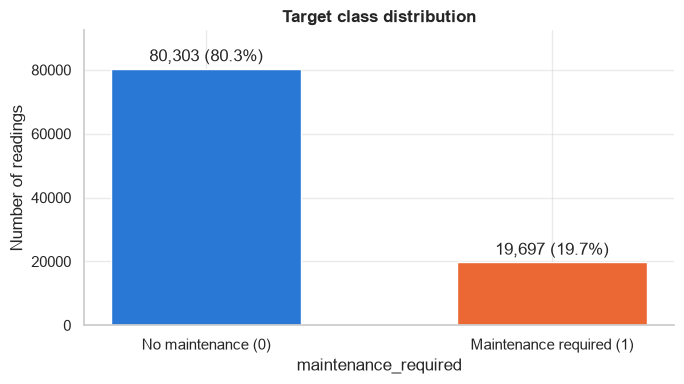

Baseline that always predicts 'no maintenance':


,score
accuracy,0.8030
recall (class 1),0.0000
F1 (class 1),0.0000
PR-AUC of a random scorer (= prevalence),0.1961


In [27]:
target_summary = df[TARGET].value_counts().sort_index().to_frame("count")
target_summary["percent"] = (target_summary["count"] / len(df) * 100).round(2)
display(target_summary)
print(f"Imbalance ratio (class 0 : class 1) = {target_summary.loc[0, 'count'] / target_summary.loc[1, 'count']:.2f} : 1")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([CLASS_LABELS[c] for c in target_summary.index], target_summary["count"],
              color=[CLASS_COLORS[c] for c in target_summary.index], edgecolor="white", width=0.55)
ax.bar_label(bars, labels=[f"{n:,} ({p:.1f}%)" for n, p in zip(target_summary["count"], target_summary["percent"])],
             padding=3)
ax.set_ylim(0, target_summary["count"].max() * 1.15)
style_ax(ax, "Target class distribution", "maintenance_required", "Number of readings")
plt.tight_layout()
plt.show()

# A "model" that never raises an alert: predicts 0 for every reading.
always_no = np.zeros(len(df), dtype=int)
baseline = pd.Series({
    "accuracy": accuracy_score(df[TARGET], always_no),
    "recall (class 1)": recall_score(df[TARGET], always_no, zero_division=0),
    "F1 (class 1)": f1_score(df[TARGET], always_no, zero_division=0),
    "PR-AUC of a random scorer (= prevalence)": average_precision_score(df[TARGET], np.random.default_rng(42).random(len(df))),
}).round(4)
print("Baseline that always predicts 'no maintenance':")
display(baseline.to_frame("score"))

**Insight:** 80,303 readings (80.3%) need no maintenance and 19,697 (19.7%) do, about 4.1 : 1. A model that never
raises an alert already scores **80.3% accuracy** while catching **0%** of the machines that need maintenance, so
accuracy is misleading here. Because a missed positive means a machine failing unexpectedly (unplanned downtime),
models should be compared on **recall** and **F1** for class 1 and on **PR-AUC**, whose no-skill baseline is
about 0.197 (the positive rate) rather than 0.5. Use a stratified split (and class weights or threshold
tuning) so the 19.7% minority class is handled deliberately.

## (b) Correlation heatmap of numeric columns (including the target)

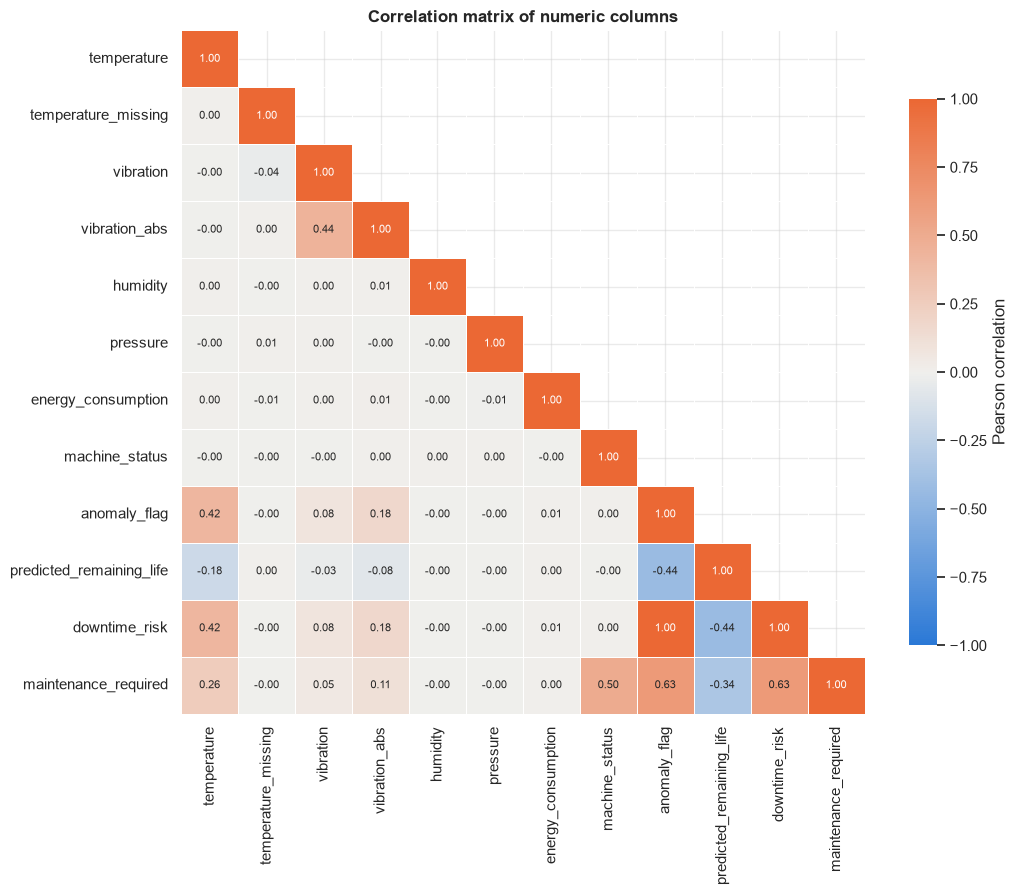

Correlation with maintenance_required (sorted):


,corr_with_target
anomaly_flag,0.6317
downtime_risk,0.6317
machine_status,0.5038
temperature,0.2623
vibration_abs,0.1132
vibration,0.0513
energy_consumption,0.0014
pressure,-0.0019
temperature_missing,-0.0032
humidity,-0.0038


In [28]:
from matplotlib.colors import LinearSegmentedColormap

# machine_id is a category label (see problem statement), so it is left out of the correlation matrix.
corr_columns = ["temperature", "temperature_missing", "vibration", "vibration_abs", "humidity", "pressure",
                "energy_consumption", "machine_status", "anomaly_flag", "predicted_remaining_life",
                "downtime_risk", TARGET]
corr = df[corr_columns].corr()

diverging = LinearSegmentedColormap.from_list("blue_gray_orange", ["#2a78d6", "#f0efec", "#eb6834"])
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=diverging, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
style_ax(ax, "Correlation matrix of numeric columns", "", "")
plt.tight_layout()
plt.show()

print("Correlation with maintenance_required (sorted):")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(4).to_frame("corr_with_target"))

**Insight:** The strongest linear relationships with the target all come from **derived** columns:
`anomaly_flag` and `downtime_risk` (both 0.63, and perfectly correlated with each other at 1.00),
`machine_status` (0.50) and `predicted_remaining_life` (-0.34). Among the raw sensors only `temperature` (0.26)
and `vibration_abs` (0.11) show any signal; `humidity`, `pressure`, `energy_consumption` and
`temperature_missing` are all within +/-0.004 of zero, and the sensors are essentially uncorrelated with each other.
Pearson correlation only measures linear effects, so sections (c) and (g) look at the full distributions.

## (c) Sensor readings vs target

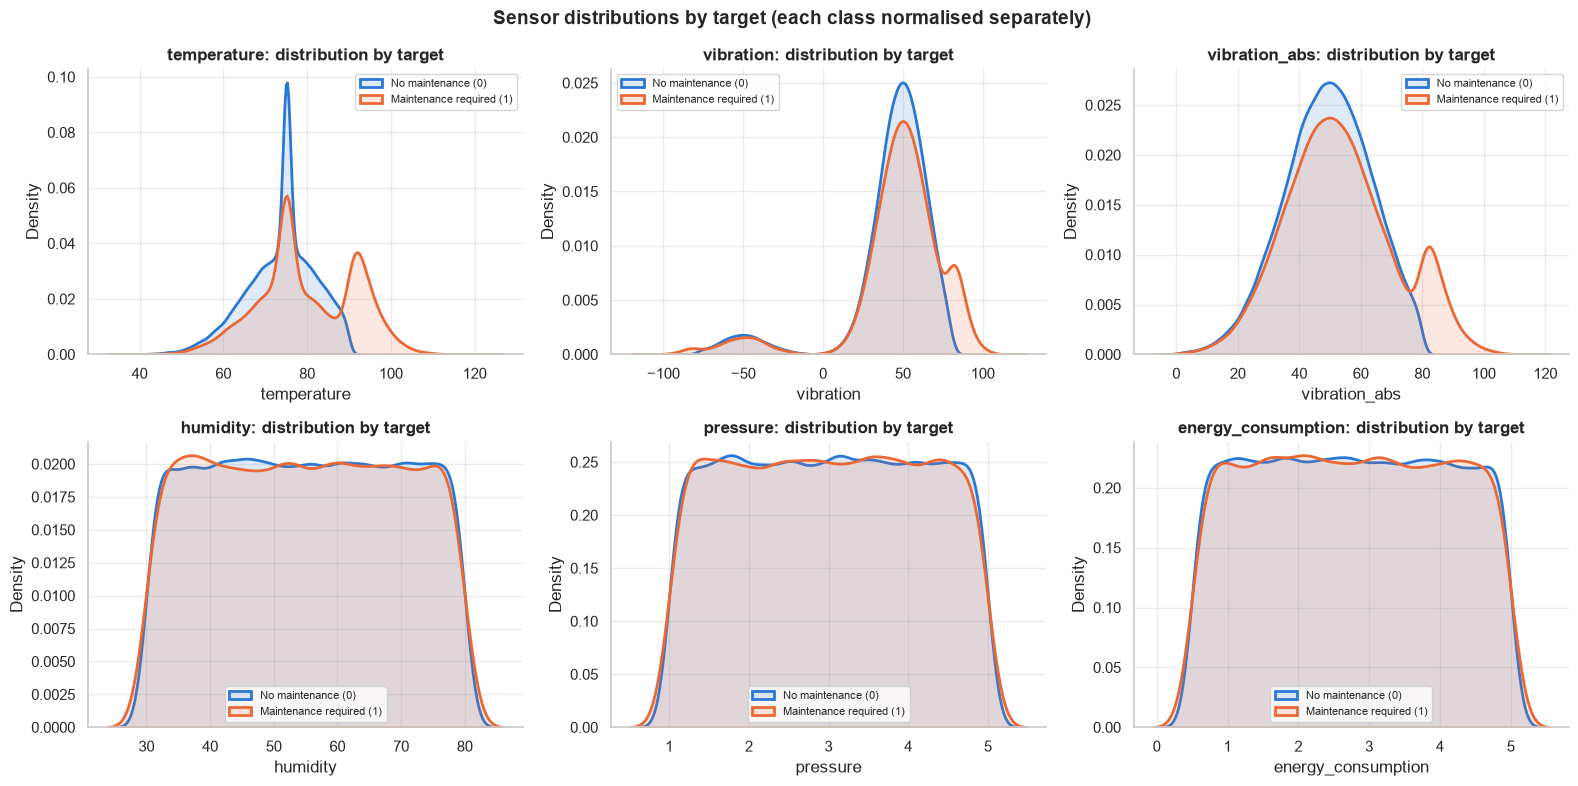

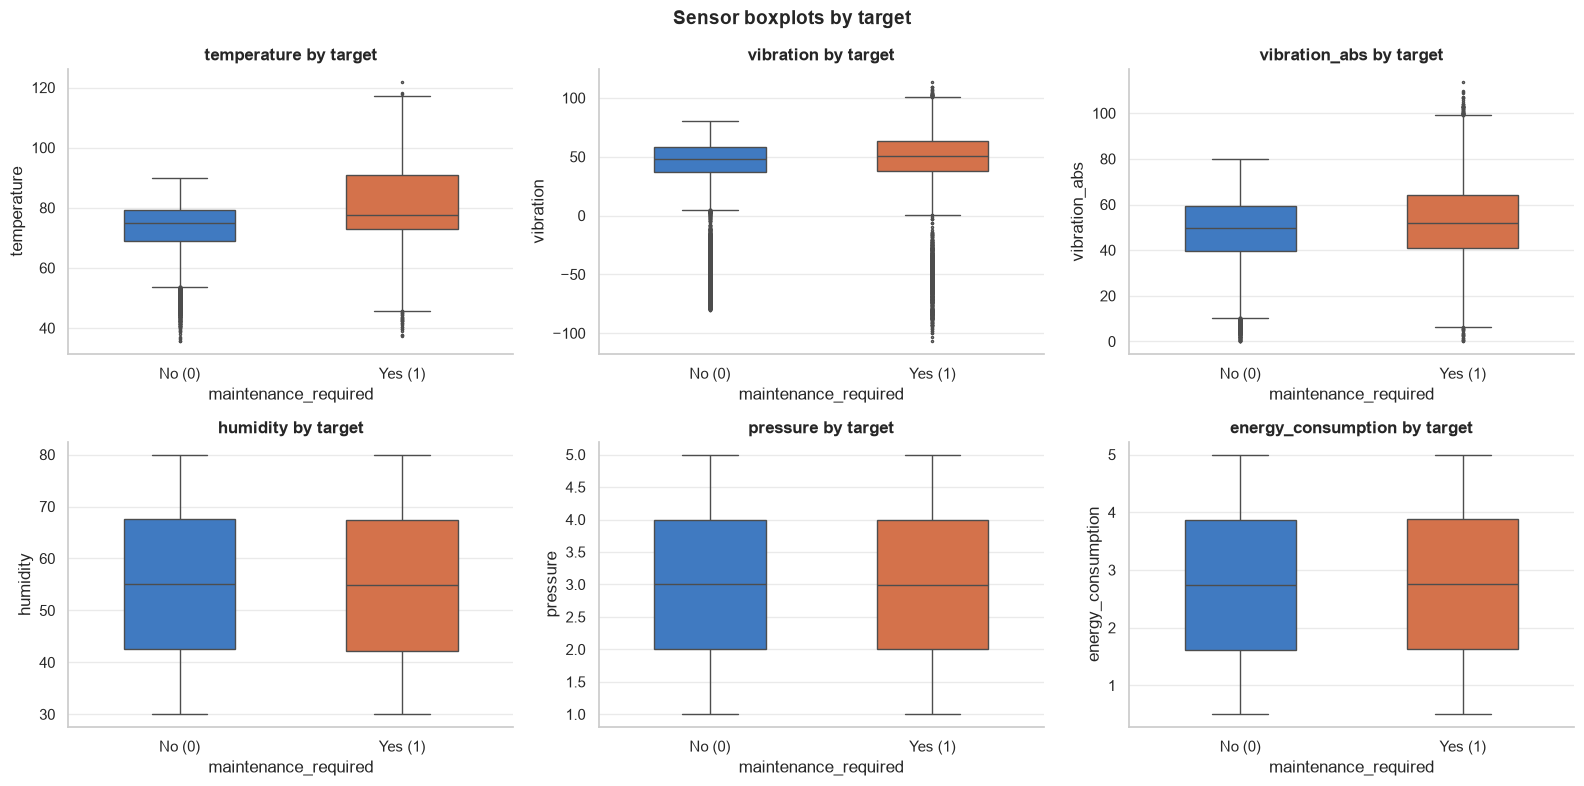

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for column, ax in zip(SENSORS, axes.ravel()):
    plot_by_class(df, column, kind="kde", ax=ax)
fig.suptitle("Sensor distributions by target (each class normalised separately)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for column, ax in zip(SENSORS, axes.ravel()):
    plot_by_class(df, column, kind="box", ax=ax)
fig.suptitle("Sensor boxplots by target", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [30]:
group_stats = df.groupby(TARGET)[SENSORS + ["temperature_missing"]].agg(["mean", "median"]).T.unstack()
group_stats.columns = [f"{stat}_target={cls}" for cls, stat in group_stats.columns]
group_stats["mean_difference (1-0)"] = group_stats["mean_target=1"] - group_stats["mean_target=0"]
print("Group means / medians by target:")
display(group_stats.round(3))

# Does any sensor reach values that NEVER occur when no maintenance is needed?
threshold_rows = []
for column in SENSORS:
    class0_max = df.loc[df[TARGET] == 0, column].max()
    above = df[column] > class0_max
    threshold_rows.append({
        "sensor": column,
        "max when target=0": class0_max,
        "max when target=1": df.loc[df[TARGET] == 1, column].max(),
        "readings above class-0 max": int(above.sum()),
        "maintenance rate above class-0 max": df.loc[above, TARGET].mean() if above.any() else np.nan,
    })
print("Readings above the highest value ever seen in class 0:")
display(pd.DataFrame(threshold_rows).set_index("sensor").round(3))

beyond_normal = (df["temperature"] > 90) | (df["vibration_abs"] > 80)
print(f"Readings with temperature > 90 or |vibration| > 80: {beyond_normal.sum():,} "
      f"-> {beyond_normal.sum() / df[TARGET].sum():.1%} of all maintenance cases; "
      f"maintenance rate among the remaining readings: {df.loc[~beyond_normal, TARGET].mean():.1%}")

Group means / medians by target:


,mean_target=0,median_target=0,mean_target=1,median_target=1,mean_difference (1-0)
temperature,73.831,74.92,79.970,77.47,6.139
vibration,42.584,48.19,46.343,50.58,3.759
vibration_abs,49.177,49.53,53.437,51.90,4.261
humidity,55.023,55.01,54.884,54.85,-0.138
pressure,3.002,3.01,2.996,2.99,-0.006
energy_consumption,2.746,2.74,2.751,2.75,0.005
temperature_missing,0.141,0.00,0.138,0.00,-0.003


Readings above the highest value ever seen in class 0:


,max when target=0,max when target=1,readings above class-0 max,maintenance rate above class-0 max
sensor,,,,
temperature,90.0,121.94,5832,1.0
vibration,80.0,113.80,2133,1.0
vibration_abs,80.0,113.80,2284,1.0
humidity,80.0,80.00,0,NaN
pressure,5.0,5.00,0,NaN
energy_consumption,5.0,5.00,0,NaN


Readings with temperature > 90 or |vibration| > 80: 7,989 -> 40.6% of all maintenance cases; maintenance rate among the remaining readings: 12.7%


**Insight:** `humidity`, `pressure` and `energy_consumption` have virtually identical distributions in both
classes (mean differences of -0.14 %RH, -0.006 bar and +0.005 kWh), and `temperature_missing` is 14.1% vs 13.8%,
so on their own these carry no signal. The signal sits in the **upper tails** of `temperature` and vibration:
when no maintenance is needed, temperature never exceeds **90 °C** and |vibration| never exceeds **80 mm/s**, but
5,832 readings are above 90 °C and 2,284 above 80 mm/s, and **every one of them** is `maintenance_required = 1`.
Together these 7,989 readings cover 40.6% of the maintenance cases; the other 59.4% have sensor values inside the
normal range, which is why the means only move by about +6 °C and +4 mm/s. Tree-based models can pick up these
threshold effects much more easily than a linear model.

## (d) machine_status vs target

,target=0,target=1,total,maintenance_rate
machine_status,,,,
0 - idle,8776,1076,9852,0.1092
1 - running,71527,8564,80091,0.1069
2 - failure,0,10057,10057,1.0000


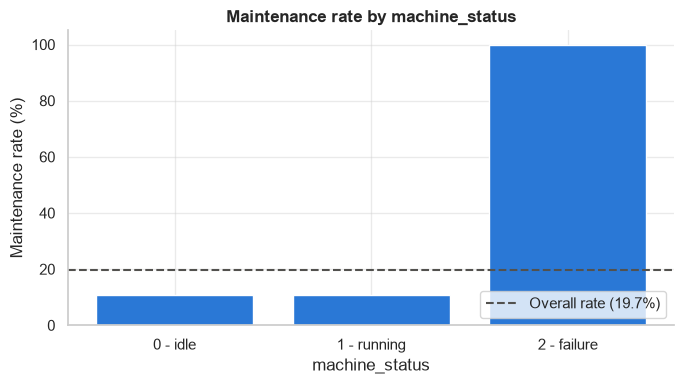

failure_type when machine_status = 2 (failure):


,readings
failure_type,
Vibration Issue,3129
Overheating,1989
Pressure Drop,1969
Normal,1956
Electrical Fault,1014


In [31]:
status_names = {0: "0 - idle", 1: "1 - running", 2: "2 - failure"}
status_table = target_crosstab(df, "machine_status").rename(index=status_names)
display(status_table)

plot_rate_bars(status_table["maintenance_rate"], "Maintenance rate by machine_status", "machine_status",
               figsize=(7, 4))
plt.tight_layout()
plt.show()

print("failure_type when machine_status = 2 (failure):")
display(df.loc[df["machine_status"] == 2, "failure_type"].value_counts().to_frame("readings"))

**Insight:** Idle (10.9%) and running (10.7%) machines have almost the same maintenance rate, but **all 10,057
readings with `machine_status = 2` (failure) are `maintenance_required = 1`**, i.e. 51% of all positives are
explained by the status alone. Status 2 also contains every non-Normal `failure_type` (8,101 rows) plus 1,956 rows
labelled Normal. A machine that is *already* in failure state is the outcome we want to anticipate, not an input
available in advance, so `machine_status` is treated as a leakage risk in section (g).

## (e) Maintenance rate per machine

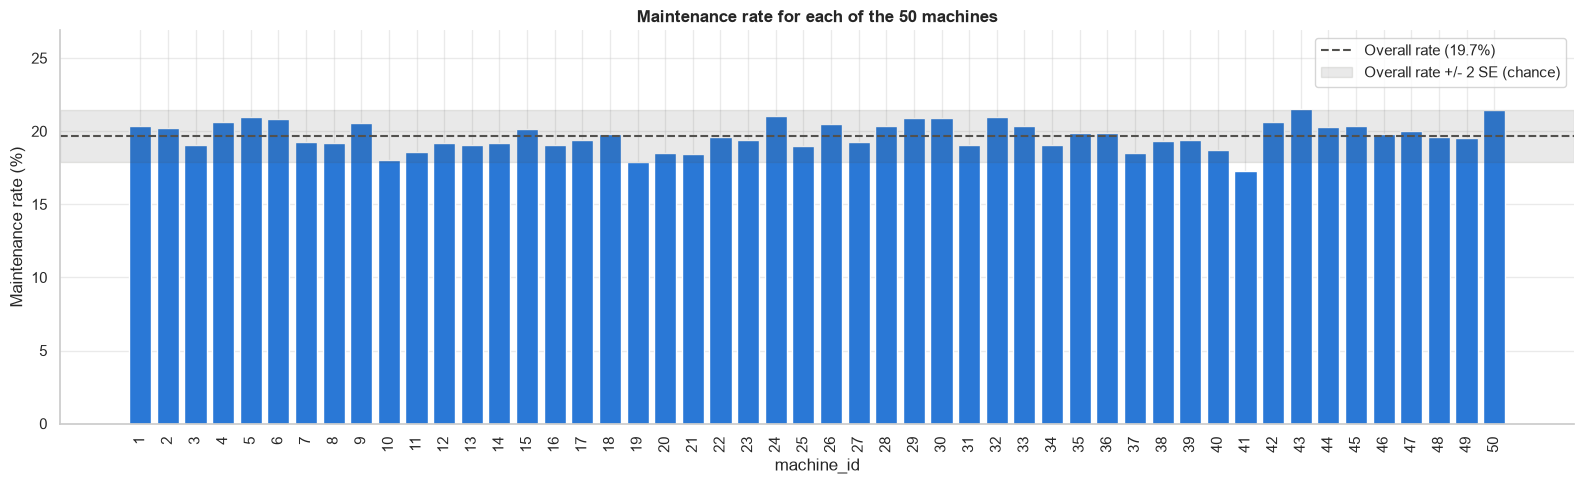

Readings per machine: min 1,906, max 2,092
Machine rates: min 17.29% (machine 41), max 21.51% (machine 43)
Std of machine rates: observed 0.0095 vs expected from chance 0.0089
Machines outside +/- 2 SE: 3 of 50 (about 2.5 expected by chance)


In [32]:
machine_table = rate_table(df, "machine_id")
machine_rates = machine_table["maintenance_rate"]

fig, ax = plt.subplots(figsize=(16, 5))
plot_rate_bars(machine_rates, "Maintenance rate for each of the 50 machines", "machine_id", ax=ax, rotate=90)

# Band of +/- 2 standard errors expected from pure chance for a machine with the average number of readings.
expected_se = np.sqrt(OVERALL_RATE * (1 - OVERALL_RATE) / machine_table["readings"].mean())
ax.axhspan((OVERALL_RATE - 2 * expected_se) * 100, (OVERALL_RATE + 2 * expected_se) * 100,
           color="#52514e", alpha=0.12, label="Overall rate +/- 2 SE (chance)")
ax.set_ylim(0, machine_rates.max() * 100 * 1.25)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Readings per machine: min {machine_table['readings'].min():,}, max {machine_table['readings'].max():,}")
print(f"Machine rates: min {machine_rates.min():.2%} (machine {machine_rates.idxmin()}), "
      f"max {machine_rates.max():.2%} (machine {machine_rates.idxmax()})")
print(f"Std of machine rates: observed {machine_rates.std():.4f} vs expected from chance {expected_se:.4f}")
print(f"Machines outside +/- 2 SE: {((machine_rates - OVERALL_RATE).abs() > 2 * expected_se).sum()} of 50 "
      f"(about {0.05 * 50:.1f} expected by chance)")

**Insight:** Each machine contributes 1,906-2,092 readings and its maintenance rate ranges only from **17.3%
(machine 41) to 21.5% (machine 43)**. The spread between machines (std 0.0095) is about the size expected from
random sampling alone (0.0089), and only 3 of 50 machines sit outside the +/-2 SE chance band (about 2.5 would be
expected by chance), so maintenance
is **not meaningfully machine-dependent**. A one-hot `machine_id` feature would add 50 columns for little gain and
risks overfitting to machine identity; per-machine information is more useful as a baseline for normalising sensor
readings (section h).

## (f) Time patterns - hour of day, day of week and date range

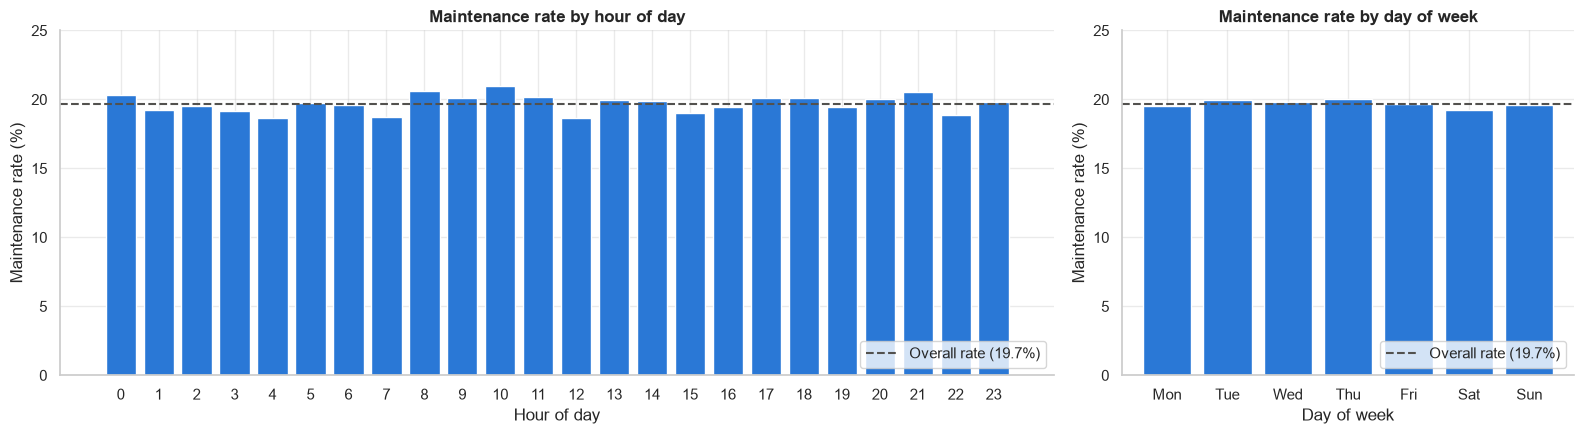

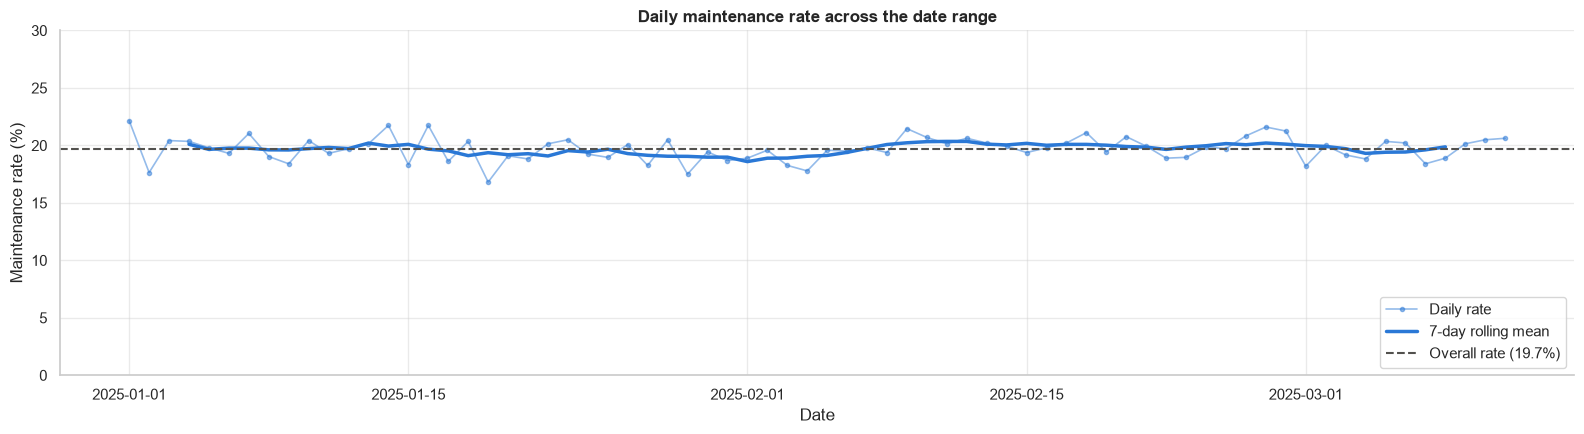

Hour-of-day rates: 18.65% to 21.00%
Day-of-week rates: 19.26% to 20.00%
Daily rates over 70 days: 16.81% to 22.15%
First half vs second half of the period: 19.46% vs 19.93%

P(target | previous reading of the same machine):


current target,0,1
previous target,,
0.0,0.8045,0.1955
1.0,0.7976,0.2024


In [33]:
time_df = df.assign(hour=df["timestamp"].dt.hour, day_of_week=df["timestamp"].dt.day_name().str[:3],
                    date=df["timestamp"].dt.normalize())
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

hour_rates = rate_table(time_df, "hour")["maintenance_rate"]
dow_table = rate_table(time_df, "day_of_week").reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
plot_rate_bars(hour_rates, "Maintenance rate by hour of day", "Hour of day", ax=axes[0])
plot_rate_bars(dow_table["maintenance_rate"], "Maintenance rate by day of week", "Day of week", ax=axes[1])
for ax in axes:
    ax.set_ylim(0, 25)
plt.tight_layout()
plt.show()

daily = rate_table(time_df, "date")
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(daily.index, daily["maintenance_rate"] * 100, color="#2a78d6", linewidth=1.2, alpha=0.5, marker="o",
        markersize=3, label="Daily rate")
ax.plot(daily.index, daily["maintenance_rate"].rolling(7, center=True).mean() * 100, color="#2a78d6", linewidth=2.5,
        label="7-day rolling mean")
ax.axhline(OVERALL_RATE * 100, color="#52514e", linestyle="--", linewidth=1.5, label=f"Overall rate ({OVERALL_RATE:.1%})")
ax.set_ylim(0, 30)
ax.legend(loc="lower right")
style_ax(ax, "Daily maintenance rate across the date range", "Date", "Maintenance rate (%)")
plt.tight_layout()
plt.show()

print(f"Hour-of-day rates: {hour_rates.min():.2%} to {hour_rates.max():.2%}")
print(f"Day-of-week rates: {dow_table['maintenance_rate'].min():.2%} to {dow_table['maintenance_rate'].max():.2%}")
print(f"Daily rates over {len(daily)} days: {daily['maintenance_rate'].min():.2%} to {daily['maintenance_rate'].max():.2%}")
print(f"First half vs second half of the period: {df[TARGET].iloc[:50_000].mean():.2%} vs {df[TARGET].iloc[50_000:].mean():.2%}")

# Is the label "sticky"? Compare each reading with the same machine's previous reading.
ordered = df.sort_values(["machine_id", "timestamp"])
previous_target = ordered.groupby("machine_id")[TARGET].shift()
print("\nP(target | previous reading of the same machine):")
display(pd.crosstab(previous_target, ordered[TARGET], normalize="index",
                    rownames=["previous target"], colnames=["current target"]).round(4))

**Insight:** There is no meaningful time pattern. Hourly rates stay between **18.7% and 21.0%**, day-of-week rates
between **19.3% and 20.0%**, and the daily rate over the 70 days moves between 16.8% and 22.2% around 19.7% with no
trend (the 7-day rolling mean stays flat; first half 19.5% vs second half 19.9%). The label is also not "sticky": after a reading
that needed maintenance, the same machine's next reading needs maintenance 20.2% of the time, versus 19.6% after
a normal reading. Calendar features are therefore unlikely to help much, and because positives are scattered
rather than clustered in time, a chronological train/test split should give similar class balance to a random
stratified one.

## (g) Data leakage check - derived columns

The problem statement lists `machine_status`, `anomaly_flag`, `predicted_remaining_life`, `failure_type` and
`downtime_risk` as **derived** columns. If any of them is computed from (or alongside) the target, a model using
them would look excellent in testing but be useless as an early-warning system. We check whether they reveal
the target deterministically.

In [34]:
print("failure_type vs target:")
display(target_crosstab(df, "failure_type").sort_values("total", ascending=False))

print("anomaly_flag vs target:")
display(target_crosstab(df, "anomaly_flag"))

print("downtime_risk vs target (all distinct values):")
display(target_crosstab(df, "downtime_risk"))

print("anomaly_flag vs downtime_risk > 0:")
display(pd.crosstab(df["anomaly_flag"], df["downtime_risk"] > 0, colnames=["downtime_risk > 0"]))

failure_type vs target:


,target=0,target=1,total,maintenance_rate
failure_type,,,,
Normal,80303,11596,91899,0.1262
Vibration Issue,0,3129,3129,1.0000
Overheating,0,1989,1989,1.0000
Pressure Drop,0,1969,1969,1.0000
Electrical Fault,0,1014,1014,1.0000


anomaly_flag vs target:


,target=0,target=1,total,maintenance_rate
anomaly_flag,,,,
0,80303,10781,91084,0.1184
1,0,8916,8916,1.0000


downtime_risk vs target (all distinct values):


,target=0,target=1,total,maintenance_rate
downtime_risk,,,,
0.00,80303,10781,91084,0.1184
0.88,0,1,1,1.0000
0.92,0,1,1,1.0000
0.93,0,1,1,1.0000
0.94,0,1,1,1.0000
0.97,0,2,2,1.0000
0.98,0,3,3,1.0000
0.99,0,3,3,1.0000
1.00,0,8904,8904,1.0000


anomaly_flag vs downtime_risk > 0:


downtime_risk > 0,False,True
anomaly_flag,,
0,91084,0
1,0,8916


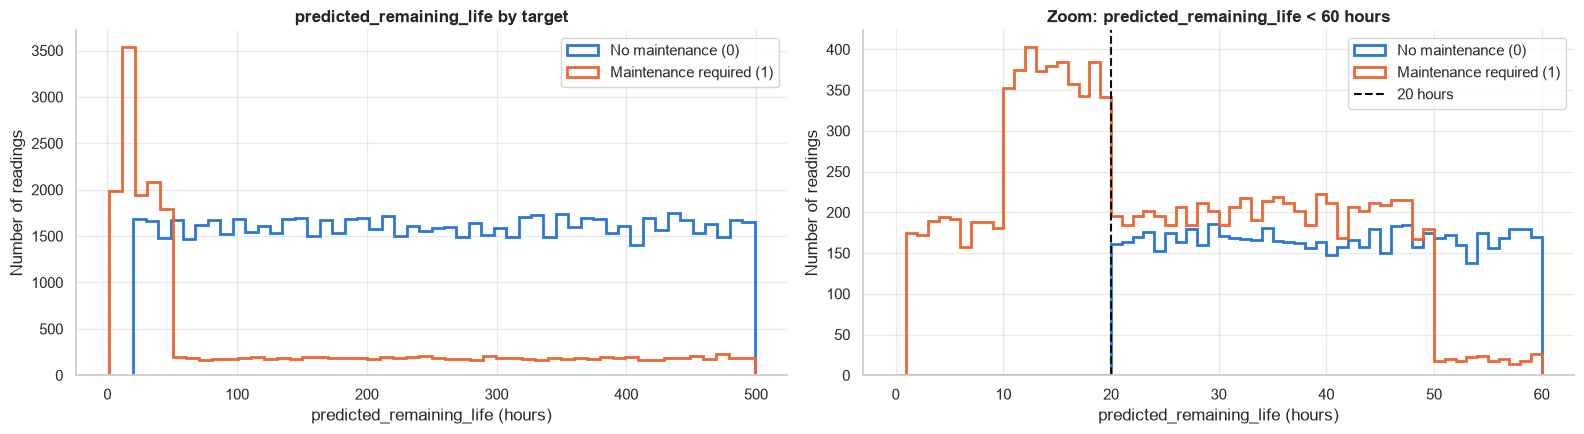

,count,mean,std,min,25%,50%,75%,max
maintenance_required,,,,,,,,
0,80303.0,259.76,138.50,20.0,140.0,259.0,379.0,499.0
1,19697.0,130.34,150.59,1.0,18.0,42.0,235.0,499.0


predicted_remaining_life < 20 vs target:


maintenance_required,0,1
remaining_life < 20,,
False,80303,14365
True,0,5332


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for cls in (0, 1):
    axes[0].hist(df.loc[df[TARGET] == cls, "predicted_remaining_life"], bins=50, color=CLASS_COLORS[cls],
                 histtype="step", linewidth=2, label=CLASS_LABELS[cls])
axes[0].legend()
style_ax(axes[0], "predicted_remaining_life by target", "predicted_remaining_life (hours)", "Number of readings")

low_life = df[df["predicted_remaining_life"] < 60]
for cls in (0, 1):
    axes[1].hist(low_life.loc[low_life[TARGET] == cls, "predicted_remaining_life"], bins=np.arange(0, 61, 1),
                 color=CLASS_COLORS[cls], histtype="step", linewidth=2, label=CLASS_LABELS[cls])
axes[1].axvline(20, color="#0b0b0b", linestyle="--", linewidth=1.5, label="20 hours")
axes[1].legend()
style_ax(axes[1], "Zoom: predicted_remaining_life < 60 hours", "predicted_remaining_life (hours)", "Number of readings")
plt.tight_layout()
plt.show()

display(df.groupby(TARGET)["predicted_remaining_life"].describe().round(2))
print("predicted_remaining_life < 20 vs target:")
display(pd.crosstab(df["predicted_remaining_life"] < 20, df[TARGET], rownames=["remaining_life < 20"]))

In [36]:
# Combine the derived columns into one rule and compare it with the target.
derived_rule = ((df["failure_type"] != "Normal") | (df["anomaly_flag"] == 1) |
                (df["machine_status"] == 2) | (df["predicted_remaining_life"] < 20)).astype(int)

print("Rule: failure_type != Normal OR anomaly_flag = 1 OR machine_status = 2 OR predicted_remaining_life < 20")
display(pd.crosstab(derived_rule, df[TARGET], rownames=["rule"], colnames=[TARGET]))
print(f"Rule matches the target on {(derived_rule == df[TARGET]).mean():.4%} of rows")

# How many positives does each derived condition explain?
conditions = {
    "failure_type != Normal": df["failure_type"] != "Normal",
    "anomaly_flag = 1 (= downtime_risk > 0)": df["anomaly_flag"] == 1,
    "machine_status = 2": df["machine_status"] == 2,
    "predicted_remaining_life < 20": df["predicted_remaining_life"] < 20,
}
coverage = pd.DataFrame({
    "rows": {k: int(v.sum()) for k, v in conditions.items()},
    "maintenance rate in these rows": {k: df.loc[v, TARGET].mean() for k, v in conditions.items()},
    "share of all positives": {k: df.loc[v, TARGET].sum() / df[TARGET].sum() for k, v in conditions.items()},
}).round(4)
display(coverage)

Rule: failure_type != Normal OR anomaly_flag = 1 OR machine_status = 2 OR predicted_remaining_life < 20


maintenance_required,0,1
rule,,
0,80303,0
1,0,19697


Rule matches the target on 100.0000% of rows


,rows,maintenance rate in these rows,share of all positives
failure_type != Normal,8101,1.0,0.4113
anomaly_flag = 1 (= downtime_risk > 0),8916,1.0,0.4527
machine_status = 2,10057,1.0,0.5106
predicted_remaining_life < 20,5332,1.0,0.2707


**Insight:** Your hypothesis is confirmed, and the leak is even wider. Every non-Normal `failure_type`
(8,101 rows), every `anomaly_flag = 1` row (8,916) and every `downtime_risk > 0` row (8,916) is
`maintenance_required = 1`, with **zero exceptions**; `anomaly_flag` and `downtime_risk > 0` mark exactly the same
rows. In addition, every `machine_status = 2` row is positive, and `predicted_remaining_life` splits the classes at
a hard threshold: class 0 never goes below **20 hours** while all 5,332 readings below 20 hours are positive.
Combined, `failure_type != Normal OR anomaly_flag = 1 OR machine_status = 2 OR predicted_remaining_life < 20`
reproduces the target on **100% of the 100,000 rows**, so the label was almost certainly generated from these columns.

**Conclusion for modelling:**
- **Exclude** `failure_type`, `anomaly_flag`, `downtime_risk` and `machine_status` from the main model. They describe
  a fault/anomaly that has already been detected (or the failure itself), so they are not available *before* the
  event the alert system is meant to prevent, and they give a trivial 100% score.
- **Exclude** `predicted_remaining_life` from the main model as well: it is an output of another predictive model and
  the target is a threshold on it (< 20 h). If the team wants to use it, report it only in a separate, clearly
  labelled "with derived features" experiment.
- The main model should use **sensor readings + engineered features only** (temperature, vibration/vibration_abs,
  humidity, pressure, energy_consumption, temperature_missing, time and per-machine features). Its realistic ceiling
  is lower: about 40.6% of positives are separable by the sensor thresholds in section (c), and the rest have
  normal-looking sensor values.

## (h) Feature-engineering ideas justified by the EDA

In [37]:
# How often does each machine report? This decides how rolling windows should be defined.
gaps_minutes = (df.sort_values(["machine_id", "timestamp"]).groupby("machine_id")["timestamp"].diff()
                .dt.total_seconds() / 60)
print("Minutes between consecutive readings of the same machine:")
display(gaps_minutes.describe().round(1).to_frame("minutes"))

# Sensor deviation from the machine's own typical value: is the per-machine baseline different between machines?
machine_medians = df.groupby("machine_id")[["temperature", "vibration_abs"]].median()
print("Spread of per-machine median sensor values across the 50 machines:")
display(machine_medians.describe().round(2))

Minutes between consecutive readings of the same machine:


,minutes
count,99950.0
mean,50.0
std,49.3
min,1.0
25%,15.0
50%,35.0
75%,69.0
max,514.0


Spread of per-machine median sensor values across the 50 machines:


,temperature,vibration_abs
count,50.00,50.00
mean,75.07,49.97
std,0.30,0.43
min,74.46,48.73
25%,74.84,49.67
50%,75.08,49.94
75%,75.28,50.33
max,75.82,50.76


**Insight:** Readings for one machine arrive irregularly - every **35 minutes** at the median, ranging from 1 to 514
minutes - so rolling features should use **time-based windows** (e.g. `rolling("6h")` on each machine's series) or a
fixed number of past readings, computed only from *past* readings to avoid look-ahead leakage.

Candidate features and why:

| Feature | Justification from the EDA |
|---|---|
| `temp_over_90`, `vib_abs_over_80` (or a model that can learn thresholds) | Section (c): above these values every reading needs maintenance (40.6% of positives). |
| `vibration_abs` (in addition to raw `vibration`) | Section (b)/(c): the magnitude correlates more with the target (0.11) than signed vibration (0.05). |
| Per-machine rolling mean / max of `temperature` and `vibration_abs` (e.g. last 3-6 readings) | Captures a machine heating up or shaking more over time rather than one noisy reading. Should be validated: section (f) showed the label itself is not persistent between consecutive readings. |
| Deltas: current reading minus previous reading of the same machine, and minus the machine's rolling mean | Sudden jumps relative to the machine's own baseline are a classic early-warning signal. Machine medians differ very little (temperature 74.5-75.8 °C, vibration_abs 48.7-50.8 mm/s), so deviations are comparable across machines. |
| `temperature_missing` | Keep as a cheap flag (missingness is 14% in both classes), but the EDA shows almost no signal; drop if it does not help in validation. |
| `hour`, `day_of_week` (cyclical sin/cos for hour) | Section (f) found no visible effect; include once to confirm, expect low importance. |
| Readings since the machine's previous high-temperature/high-vibration event | Turns isolated threshold hits into a "recent stress" history without using leaky derived columns. |

**Not to use:** `failure_type`, `anomaly_flag`, `downtime_risk`, `machine_status`, `predicted_remaining_life`
(section g), and one-hot `machine_id` (section e shows no machine effect beyond chance).

## (i) Summary of Key EDA Findings

- **Imbalanced target:** 19,697 of 100,000 readings (19.7%) need maintenance (about 4.1 : 1). Always predicting
  "no maintenance" scores 80.3% accuracy with 0% recall, so models are evaluated on recall, F1 and PR-AUC
  (no-skill PR-AUC = 0.197).
- **Severe leakage in derived columns:** `failure_type != Normal`, `anomaly_flag = 1` (identical to
  `downtime_risk > 0`), `machine_status = 2` and `predicted_remaining_life < 20` each imply maintenance with zero
  exceptions, and together reproduce the target on 100% of rows. These columns are excluded from the main model.
- **Sensor signal is concentrated in thresholds:** temperature above 90 °C (5,832 readings) or |vibration| above
  80 mm/s (2,284 readings) always means maintenance; these cover 40.6% of positives. Overall correlations are
  modest (temperature 0.26, vibration_abs 0.11).
- **Weak sensors:** humidity, pressure and energy_consumption have near-identical distributions in both classes
  (|correlation| < 0.004) and are unlikely to help on their own.
- **Not machine-dependent:** per-machine maintenance rates range from 17.3% to 21.5%, a spread consistent with
  chance (std 0.0095 vs 0.0089 expected; 3 of 50 machines outside +/-2 SE), so machine_id is not used as a one-hot
  feature.
- **No time pattern:** rates are flat across hour of day (18.7-21.0%), day of week (19.3-20.0%) and the 70-day
  period, and the label is not persistent between a machine's consecutive readings (20.2% vs 19.6%).
- **Timestamp parsing bug (fixed):** raw timestamps are day-first (`d/m/yyyy h:mm`); the old format-less parse
  turned 50,400 rows into NaT. Both the notebook and the cleaning script now use `format="%d/%m/%Y %H:%M"`, giving
  0 missing timestamps and a range of 1 Jan to 11 Mar 2025, one reading per minute.
- **Data quality:** 14% of temperatures were missing (imputed with machine medians and flagged), and vibration has
  6,703 negative values (kept, with `vibration_abs` added); missingness itself does not predict maintenance.